In [1]:
%cd ..

/Users/niilok/Documents/Omat_projektit/Bird-CNN


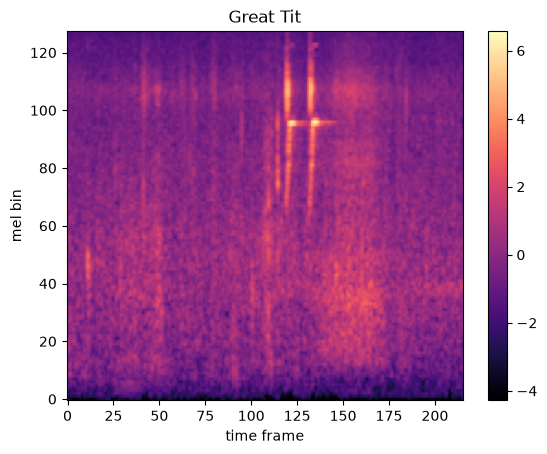

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("data/processed_metadata.csv")
row = df.sample(1).iloc[0]
plt.imshow(np.load(row["chunk_path"])[0], origin="lower", aspect="auto", cmap="magma")
plt.title(row["species"]); plt.xlabel("time frame"); plt.ylabel("mel bin"); plt.colorbar()
plt.show()

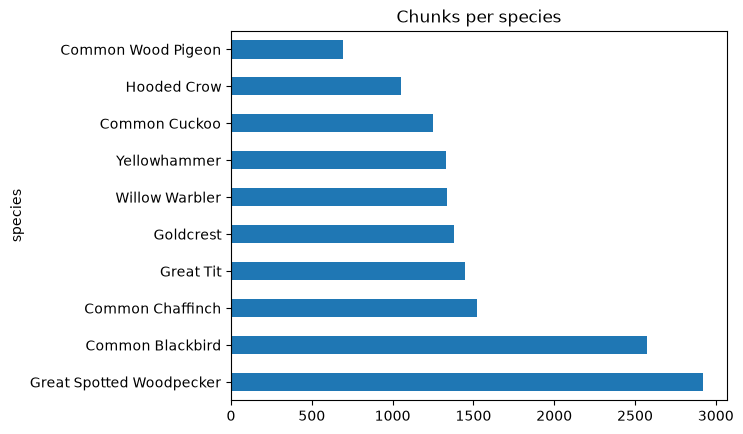

In [7]:
df["species"].value_counts().plot.barh(title="Chunks per species")
plt.show()

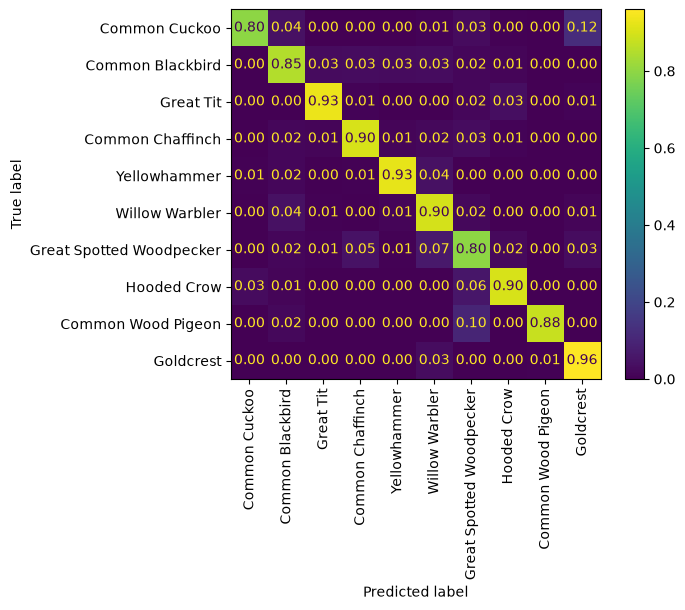

In [8]:
import torch
from sklearn.metrics import ConfusionMatrixDisplay
from src.checkpoint import load_checkpoint
from src.dataset import get_dataloaders
from src.model import BirdCNN, ModelConfig
from src.train import predict

device = "mps" if torch.backends.mps.is_available() else "cpu"
model, ckpt = load_checkpoint("checkpoints/best.pt", BirdCNN, ModelConfig)
_, _, test_loader, _ = get_dataloaders()
logits, y_true = predict(model.to(device), test_loader, device)
names = sorted(ckpt["classes"], key=ckpt["classes"].get)
ConfusionMatrixDisplay.from_predictions(
    y_true, logits.argmax(1).numpy(), display_labels=names,
    xticks_rotation=90, normalize="true", values_format=".2f",
)
plt.show()